In [1]:
from matplotlib.backends.backend_pdf import PdfPages
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import os

plt.rcParams['font.family'] = 'DeJavu Serif'
plt.rcParams['font.serif'] = ['Times New Roman']

In [2]:
dataset = 'dusz'
dataset_n = 6
session = 'A1821-190910'

smoothing = 290

In [3]:
os.chdir('..')

! python src/dusz_ratemaps_hd.py --dataset {dataset_n} --rat {session} --smooth_window {smoothing} --vel_threshold {vel_threshold}

os.chdir('notebooks')

usage: dusz_ratemaps_hd.py [-h] --dataset DATASET --rat RAT
                           [--n_hd_bins N_HD_BINS] [--n_md_bins N_MD_BINS]
                           [--n_spatial_bins N_SPATIAL_BINS] --smooth_window
                           SMOOTH_WINDOW [--vel_threshold VEL_THRESHOLD]
dusz_ratemaps_hd.py: error: argument --dataset: invalid int value: '{dataset_n}'


In [5]:
def quantify_variance(heatmap_test, heatmap_train, axis=0, verbose=False):
    """
    Quantify the variance due to a certain variable in a cross-validated manner.
    heatmaps are 2D, and are average spikes/sec across visits to each behavioral bin.
    Negative values indicate dominance of inherent variance over dimension-explained variance.
    """

    test_mean = np.nanmean(heatmap_test, axis=axis)
    train_mean = np.nanmean(heatmap_train, axis=axis)

    # Expand along `axis` so we can subtract
    if axis == 0:
        test_mean_expanded = test_mean[np.newaxis, :]
        train_mean_expanded = train_mean[np.newaxis, :]
    else:
        test_mean_expanded = test_mean[:, np.newaxis]
        train_mean_expanded = train_mean[:, np.newaxis]

    n_bins = heatmap_test.shape[axis]

    # Now compute the variance terms with occupancy weighting
    inter_var_test = np.nansum((heatmap_test - test_mean_expanded)**2)
    inter_var_train = np.nansum((heatmap_train - train_mean_expanded)**2)

    intra_var_all = np.nansum((heatmap_test - heatmap_train)**2)
    intra_var_means = n_bins * np.nansum((test_mean - train_mean)**2)

    if verbose:
        print(f"axis={axis} sum((test - test_mean)^2)={inter_var_test:.4f}")
        print(f"axis={axis} sum((train - train_mean)^2)={inter_var_train:.4f}")
        print(f"axis={axis} sum((test - train)^2)={intra_var_all:.4f}")
        print(f"axis={axis} n_bins * sum((test_mean - train_mean)^2)={intra_var_means:.4f}")
        print()
    
    estimator = 0.5 * (
        inter_var_test +
        inter_var_train -
        intra_var_all +
        intra_var_means
    )
    
    return estimator, inter_var_test, inter_var_train, intra_var_all, intra_var_means

In [30]:
n_md_bins = 17
n_hd_bins = 17

from pathlib import Path
current_file_path = Path().resolve().parent
current_file_path

raw_visits = np.load(current_file_path / f'results/{dataset}/Dataset_{dataset_n}/{session}/hd_md_raw_visits_{n_hd_bins}_{n_md_bins}.npy')

raw_visits.shape


(17, 17, 200, 39)

In [31]:
from pathlib import Path
current_file_path = Path().resolve().parent
current_file_path

n_md_bins = 17
n_hd_bins = 17


occ = np.load(current_file_path / f'results/{dataset}/Dataset_{dataset_n}/{session}/hd_md_occupancy_map_{n_hd_bins}_{n_md_bins}.npy')
np.max(occ)


3324.0

In [26]:
raw_visits[0, 0, :, 0]

array([nan,  0.,  0., nan, nan,  0., nan,  0.,  0., nan,  0., nan,  0.,
        0., nan,  0.,  0.,  0., nan, nan,  0., nan,  0., nan,  0.,  0.,
        0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0., nan,  0.,  0.,  0.,
       nan, nan,  0.,  0.,  0.,  0.,  0.,  0., nan, nan,  0.])

In [34]:
n_neurons = raw_visits.shape[3]
n_visits = raw_visits.shape[2]

n_dataset_trials = 200

mean_hd_var_results = np.zeros((n_dataset_trials, n_neurons))
mean_md_var_results = np.zeros((n_dataset_trials, n_neurons))

for dataset_trial in tqdm(range(n_dataset_trials)):
    hd_rate_map_test = np.zeros((n_md_bins, n_hd_bins, n_neurons))
    hd_rate_map_train = np.zeros((n_md_bins, n_hd_bins, n_neurons))
    hd_rate_map_test[:] = np.nan
    hd_rate_map_train[:] = np.nan
    
    for md in range(n_md_bins):
        for hd in range(n_hd_bins):
            if np.isnan(raw_visits[md, hd]).all():
                continue

            #occ_count = int(occ[md, hd])
            #visits = raw_visits[md, hd, :occ_count, :]
            visits = raw_visits[md, hd, :, :]
            np.random.shuffle(visits)
            visits = visits[:100, :]
            np.random.shuffle(visits)
            
            half = len(visits) // 2
            hd_rate_map_test[md, hd, :] = np.nanmean(visits[:half, :], axis=0)
            hd_rate_map_train[md, hd, :] = np.nanmean(visits[half:, :], axis=0)

    for i in range(n_neurons):
        mean_hd_var_results[dataset_trial, i] = quantify_variance(hd_rate_map_test[:, :, i], hd_rate_map_train[:, :, i], axis=1, verbose=False)[0]
        mean_md_var_results[dataset_trial, i] = quantify_variance(hd_rate_map_test[:, :, i], hd_rate_map_train[:, :, i], axis=0, verbose=False)[0]


100%|█████████████████████████████████████████| 200/200 [00:19<00:00, 10.21it/s]


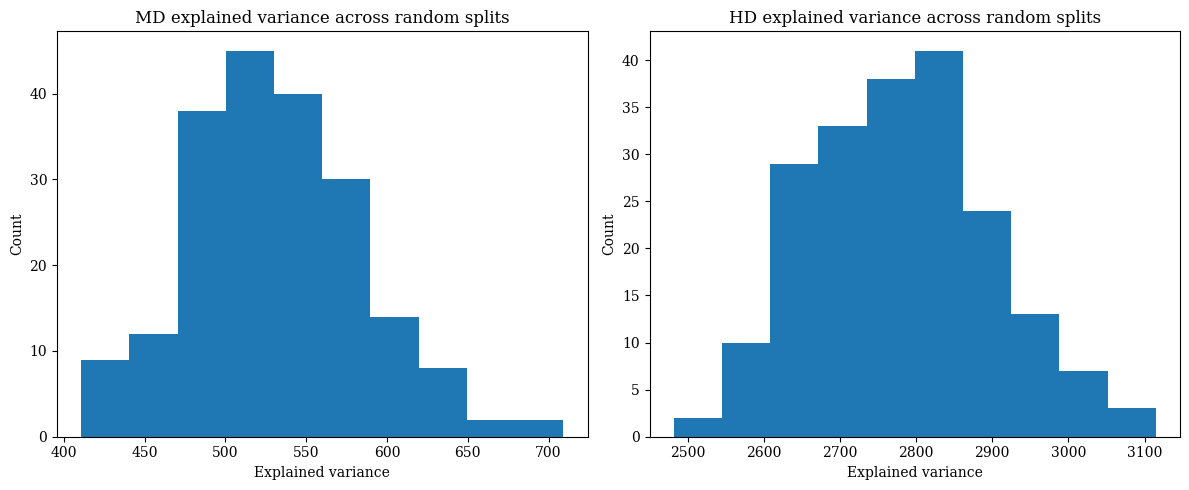

In [35]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

im1 = axs[0].hist(mean_md_var_results[:, 0])
axs[0].set_title("MD explained variance across random splits")
axs[0].set_ylabel("Count")
axs[0].set_xlabel("Explained variance")

im2 = axs[1].hist(mean_hd_var_results[:, 0])
axs[1].set_title("HD explained variance across random splits")
axs[1].set_ylabel("Count")
axs[1].set_xlabel("Explained variance")

plt.tight_layout()
plt.show()

